In [1]:
import pandas as pd
import numpy as np

# Load all csv files
users = pd.read_csv('users.csv')
organizations = pd.read_csv('organizations.csv')
subscriptions = pd.read_csv('subscriptions.csv')
user_events = pd.read_csv('user_events.csv')
support_tickets = pd.read_csv('support_tickets.csv')

# Verify shapes
print("Data shapes:")
for name, df in [('users', users), ('organizations', organizations), 
                 ('subscriptions', subscriptions), ('user_events', user_events), 
                 ('support_tickets', support_tickets)]:
    print(f"{name:20s}: {df.shape[0]} rows × {df.shape[1]} columns")

Data shapes:
users               : 420 rows × 7 columns
organizations       : 180 rows × 5 columns
subscriptions       : 420 rows × 8 columns
user_events         : 6942 rows × 5 columns
support_tickets     : 120 rows × 7 columns


In [2]:
# Inspect data quality
def inspect_data(name, df):
    print(f"\n{'='*60}")
    print(f"{name.upper()} - {df.shape[0]} rows, {df.shape[1]} columns")
    print(f"{'='*60}")
    
    print("\nData types:")
    print(df.dtypes)
    
    print("\nFirst 3 rows:")
    display(df.head(3))
    
    print("\nMissing values:")
    print(df.isnull().sum())
    
    print("\nUnique values (key columns):")
    for col in df.columns:
        if df[col].nunique() < 50 or col.endswith('_id'):
            print(f"  {col}: {df[col].nunique():,} unique values")

# Run inspection on all tables
for name, df in [('users', users), ('organizations', organizations), 
                 ('subscriptions', subscriptions), 
                 ('user_events', user_events), 
                 ('support_tickets', support_tickets)]:
    inspect_data(name, df)


USERS - 420 rows, 7 columns

Data types:
user_id                 object
organization_id         object
email                   object
is_internal               bool
created_by              object
signup_at               object
onboarding_completed      bool
dtype: object

First 3 rows:


,user_id,organization_id,email,is_internal,created_by,signup_at,onboarding_completed
0,user_0001,org_0086,user1@example.com,False,self_signup,2026-05-21,True
1,user_0002,org_0161,user2@example.com,False,self_signup,2026-08-30,True
2,user_0003,org_0129,user3@nimbus.io,True,qa_seed,2026-08-19,True



Missing values:
user_id                 0
organization_id         0
email                   0
is_internal             0
created_by              0
signup_at               0
onboarding_completed    0
dtype: int64

Unique values (key columns):
  user_id: 420 unique values
  organization_id: 165 unique values
  is_internal: 2 unique values
  created_by: 2 unique values
  onboarding_completed: 2 unique values

ORGANIZATIONS - 180 rows, 5 columns

Data types:
organization_id        object
organization_name      object
company_size           object
acquisition_channel    object
created_at             object
dtype: object

First 3 rows:


,organization_id,organization_name,company_size,acquisition_channel,created_at
0,org_0001,Company 1,1-5,organic,2026-06-27
1,org_0002,Company 2,51+,organic,2026-06-12
2,org_0003,Company 3,6-20,sales,2026-02-02



Missing values:
organization_id        0
organization_name      0
company_size           0
acquisition_channel    0
created_at             0
dtype: int64

Unique values (key columns):
  organization_id: 180 unique values
  company_size: 4 unique values
  acquisition_channel: 5 unique values

SUBSCRIPTIONS - 420 rows, 8 columns

Data types:
subscription_id      object
user_id              object
organization_id      object
plan                 object
status               object
trial_started_at     object
converted_at         object
cancelled_at        float64
dtype: object

First 3 rows:


,subscription_id,user_id,organization_id,plan,status,trial_started_at,converted_at,cancelled_at
0,sub_0001,user_0001,org_0086,starter,active,2026-05-21,2026-06-16,NaN
1,sub_0002,user_0002,org_0161,trial,trial,2026-08-30,NaN,NaN
2,sub_0003,user_0003,org_0129,internal,active,NaN,NaN,NaN



Missing values:
subscription_id       0
user_id               0
organization_id       0
plan                  0
status                0
trial_started_at     28
converted_at        204
cancelled_at        420
dtype: int64

Unique values (key columns):
  subscription_id: 420 unique values
  user_id: 420 unique values
  organization_id: 165 unique values
  plan: 5 unique values
  status: 3 unique values
  cancelled_at: 0 unique values

USER_EVENTS - 6942 rows, 5 columns

Data types:
event_id       object
user_id        object
event_name     object
occurred_at    object
ingested_at    object
dtype: object

First 3 rows:


,event_id,user_id,event_name,occurred_at,ingested_at
0,evt_000120,user_0009,create_project,2026-07-21 12:11:24,2026-07-21 12:22:14
1,evt_002991,user_0186,login,2026-05-27 21:36:38,2026-05-27 21:47:28
2,evt_002380,user_0148,view_dashboard,2026-09-23 14:57:59,2026-09-23 15:08:49



Missing values:
event_id       0
user_id        0
event_name     0
occurred_at    0
ingested_at    0
dtype: int64

Unique values (key columns):
  event_id: 6,862 unique values
  user_id: 420 unique values
  event_name: 6 unique values

SUPPORT_TICKETS - 120 rows, 7 columns

Data types:
ticket_id          object
user_id            object
created_at         object
status             object
category           object
resolution_type    object
closed_reason      object
dtype: object

First 3 rows:


,ticket_id,user_id,created_at,status,category,resolution_type,closed_reason
0,tkt_0001,user_0325,2026-08-07,resolved,onboarding,agent_resolved,NaN
1,tkt_0002,user_0209,2026-05-31,resolved,feature_request,self_serve,NaN
2,tkt_0003,user_0050,2026-05-14,awaiting_customer,technical,none,awaiting_customer



Missing values:
ticket_id           0
user_id             0
created_at          0
status              0
category            0
resolution_type     0
closed_reason      64
dtype: int64

Unique values (key columns):
  ticket_id: 120 unique values
  user_id: 103 unique values
  status: 4 unique values
  category: 4 unique values
  resolution_type: 4 unique values
  closed_reason: 4 unique values


In [3]:
# Understand Table Relationships
print("Primary key uniqueness:")
print(f"users.user_id: {users['user_id'].is_unique}")
print(f"organizations.organization_id: {organizations['organization_id'].is_unique}")
print(f"subscriptions.subscription_id: {subscriptions['subscription_id'].is_unique}")
print(f"user_events.event_id: {user_events['event_id'].is_unique}  <-- Check for duplicates!")
print(f"support_tickets.ticket_id: {support_tickets['ticket_id'].is_unique}")

print("\nForeign key coverage:")
print(f"users.organization_id matches organizations: {users['organization_id'].isin(organizations['organization_id']).mean():.1%}")
print(f"subscriptions.user_id matches users: {subscriptions['user_id'].isin(users['user_id']).mean():.1%}")
print(f"subscriptions.organization_id matches organizations: {subscriptions['organization_id'].isin(organizations['organization_id']).mean():.1%}")
print(f"user_events.user_id matches users: {user_events['user_id'].isin(users['user_id']).mean():.1%}")
print(f"support_tickets.user_id matches users: {support_tickets['user_id'].isin(users['user_id']).mean():.1%}")

Primary key uniqueness:
users.user_id: True
organizations.organization_id: True
subscriptions.subscription_id: True
user_events.event_id: False  <-- Check for duplicates!
support_tickets.ticket_id: True

Foreign key coverage:
users.organization_id matches organizations: 100.0%
subscriptions.user_id matches users: 100.0%
subscriptions.organization_id matches organizations: 100.0%
user_events.user_id matches users: 100.0%
support_tickets.user_id matches users: 100.0%


In [4]:
# Parse dates first
for col in ['trial_started_at', 'converted_at', 'cancelled_at']:
    subscriptions[col] = pd.to_datetime(subscriptions[col], errors='coerce')

# Join with users and organizations to get internal status, onboarding, and acquisition channel
subs_enriched = (
    subscriptions
    .merge(users[['user_id', 'is_internal', 'onboarding_completed']], on='user_id', how='left')
    .merge(organizations[['organization_id', 'acquisition_channel']], on='organization_id', how='left')
)

# Filter for all external users who started a trial (including those who converted to active)
external_trials = subs_enriched[
    (subs_enriched['trial_started_at'].notna()) &
    (subs_enriched['is_internal'] == False)
].copy()

# Calculate trial age in days (for active/unconverted trials, or days since trial start)
today = pd.Timestamp('2026-11-16')
external_trials['trial_age_days'] = (today - external_trials['trial_started_at']).dt.days

# Key metrics
unconverted_trials = external_trials[external_trials['status'] == 'trial']
print(f"Total external trials started: {len(external_trials)}")
print(f"Still in trial > 14 days: {(unconverted_trials['trial_age_days'] > 14).sum()}")
print(f"Still in trial > 30 days: {(unconverted_trials['trial_age_days'] > 30).sum()}")

# Conversion rate calculation (within 30 days of trial start)
external_trials['converted_within_30d'] = (
    external_trials['converted_at'].notna() &
    ((external_trials['converted_at'] - external_trials['trial_started_at']).dt.days <= 30)
)

# Complete window (trials started at least 30 days before reference date)
eligible_trials = external_trials[external_trials['trial_age_days'] >= 30].copy()

if len(eligible_trials) > 0:
    conversion_rate = eligible_trials['converted_within_30d'].mean()
    print(f"Conversion rate (30-day window): {conversion_rate:.1%}")
else:
    print("No eligible trials for conversion rate calculation")


Total external trials started: 392
Still in trial > 14 days: 176
Still in trial > 30 days: 176
Conversion rate (30-day window): 55.1%


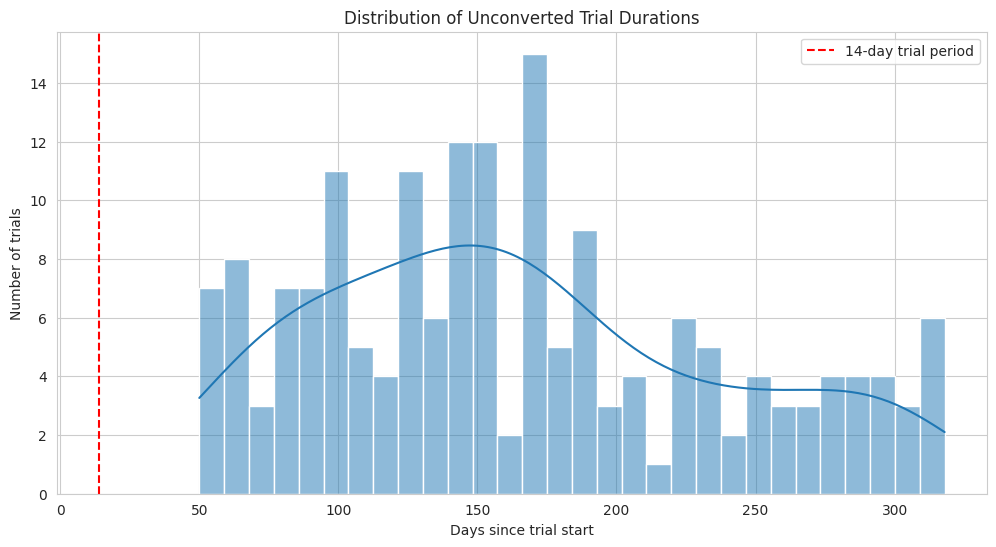

organic        : 51.1% (131 trials)
paid_search    : 58.5% (94 trials)
partner        : 51.3% (39 trials)
referral       : 58.2% (79 trials)
sales          : 57.1% (49 trials)


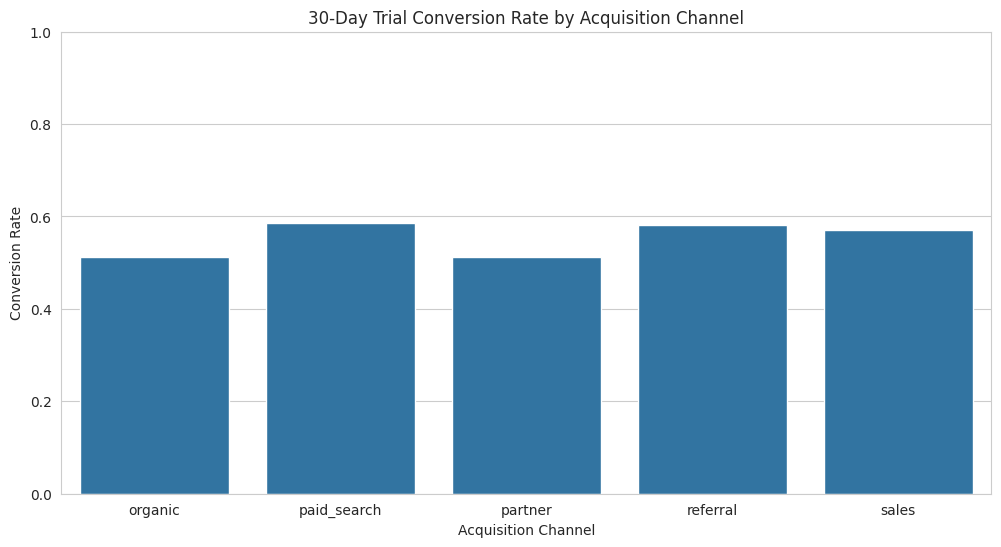

In [5]:
# Visualize key patterns

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

# Plot 1: Trial age distribution (for unconverted trials)
plt.figure(figsize=(12, 6))
sns.histplot(unconverted_trials['trial_age_days'], bins=30, kde=True)
plt.title('Distribution of Unconverted Trial Durations')
plt.xlabel('Days since trial start')
plt.ylabel('Number of trials')
plt.axvline(x=14, color='r', linestyle='--', label='14-day trial period')
plt.legend()
plt.show()

# Plot 2: Conversion rate by acquisition channel
channel_rates = (
    eligible_trials
    .groupby('acquisition_channel', as_index=False)
    .agg(conversion_rate=('converted_within_30d', 'mean'), trials=('user_id', 'count'))
)

for _, row in channel_rates.iterrows():
    print(f"{row['acquisition_channel']:15s}: {row['conversion_rate']:.1%} ({row['trials']} trials)")

plt.figure(figsize=(12, 6))
sns.barplot(data=channel_rates, x='acquisition_channel', y='conversion_rate')
plt.title('30-Day Trial Conversion Rate by Acquisition Channel')
plt.xlabel('Acquisition Channel')
plt.ylabel('Conversion Rate')
plt.ylim(0, 1)
plt.show()


In [6]:
print("External trials columns:", external_trials.columns.tolist())
print("External trials sample:")
display(external_trials.head())

onboarding_comparison = pd.crosstab(
    eligible_trials['onboarding_completed'],
    eligible_trials['converted_within_30d'],
    margins=True,
    margins_name='Overall'
)
print("Conversion counts by onboarding completion:")
print(onboarding_comparison)


External trials columns: ['subscription_id', 'user_id', 'organization_id', 'plan', 'status', 'trial_started_at', 'converted_at', 'cancelled_at', 'is_internal', 'onboarding_completed', 'acquisition_channel', 'trial_age_days', 'converted_within_30d']
External trials sample:


,subscription_id,user_id,organization_id,plan,status,trial_started_at,converted_at,cancelled_at,is_internal,onboarding_completed,acquisition_channel,trial_age_days,converted_within_30d
0,sub_0001,user_0001,org_0086,starter,active,2026-05-21,2026-06-16,NaT,False,True,paid_search,179,True
1,sub_0002,user_0002,org_0161,trial,trial,2026-08-30,NaT,NaT,False,True,referral,78,False
3,sub_0004,user_0004,org_0006,trial,trial,2026-09-25,NaT,NaT,False,False,paid_search,52,False
4,sub_0005,user_0005,org_0095,starter,active,2026-05-27,2026-05-31,NaT,False,True,referral,173,True
5,sub_0006,user_0006,org_0023,pro,active,2026-07-15,2026-07-21,NaT,False,True,organic,124,True


Conversion counts by onboarding completion:
converted_within_30d  False  True  Overall
onboarding_completed                      
False                   103    51      154
True                     73   165      238
Overall                 176   216      392


In [7]:
# Question 1: Does onboarding completion affect conversion?
onboarding_rates = eligible_trials.groupby('onboarding_completed')['converted_within_30d'].agg(['count', 'mean'])
onboarding_rates.columns = ['eligible_trials', 'conversion_rate']
print("Conversion rate by onboarding completion:")
print(onboarding_rates)

# Question 2: Which organizations have no post-conversion activity?
active_paid = subs_enriched[
    (subs_enriched['status'] == 'active') &
    (subs_enriched['plan'] != 'internal') &
    (subs_enriched['is_internal'] == False) &
    (subs_enriched['converted_at'].notna())
].copy()

# Deduplicate user_events and attach organization_id
events_clean = (
    user_events
    .drop_duplicates(subset=['event_id'])
    .merge(users[['user_id', 'organization_id']], on='user_id', how='left')
)
events_clean['occurred_at'] = pd.to_datetime(events_clean['occurred_at'], errors='coerce')

zero_event_orgs = []
for org, org_subs in active_paid.groupby('organization_id'):
    first_conversion = org_subs['converted_at'].min()
    org_events = events_clean[
        (events_clean['organization_id'] == org) &
        (events_clean['occurred_at'] >= first_conversion)
    ]
    if len(org_events) == 0:
        zero_event_orgs.append(org)

print(f"\nOrganizations with active paid users but zero post-conversion events: {len(zero_event_orgs)}")
print(zero_event_orgs[:10])


Conversion rate by onboarding completion:
                      eligible_trials  conversion_rate
onboarding_completed                                  
False                             154         0.331169
True                              238         0.693277

Organizations with active paid users but zero post-conversion events: 0
[]


In [8]:
users_with_events = active_paid['user_id'].isin(events_clean['user_id']).sum()

print("=" * 60)
print("KEY FINDINGS SUMMARY")
print("=" * 60)
print(f"1. Total external trials started: {len(external_trials)}")
print(f"2. Stale unconverted trials (>14 days): {(unconverted_trials['trial_age_days'] > 14).sum()}")
print(f"3. Conversion rate (30-day window): {conversion_rate:.1%}")
print(f"4. Organizations with no post-conversion events: {len(zero_event_orgs)}")
print(f"5. Duplicate event IDs removed: {len(user_events) - user_events['event_id'].nunique()}")

print("\nKey insights:")
print("- Trials >14 days without conversion represent stale/unconverted trials")
print("- Onboarding completion strongly impacts 30-day conversion")
print(f"- {users_with_events} of {len(active_paid)} active paid users have logged events")


KEY FINDINGS SUMMARY
1. Total external trials started: 392
2. Stale unconverted trials (>14 days): 176
3. Conversion rate (30-day window): 55.1%
4. Organizations with no post-conversion events: 0
5. Duplicate event IDs removed: 80

Key insights:
- Trials >14 days without conversion represent stale/unconverted trials
- Onboarding completion strongly impacts 30-day conversion
- 128 of 128 active paid users have logged events


In [9]:
# Complete missing breakdowns for Cohort, Company Size, Expiration & Support Tickets
df_full = (
    subscriptions
    .merge(users[['user_id', 'is_internal', 'created_by', 'signup_at', 'onboarding_completed']], on='user_id', how='left')
    .merge(organizations[['organization_id', 'company_size', 'acquisition_channel']], on='organization_id', how='left')
)

for col in ['trial_started_at', 'converted_at']:
    df_full[col] = pd.to_datetime(df_full[col], errors='coerce')
df_full['signup_at'] = pd.to_datetime(df_full['signup_at'], errors='coerce')

today = pd.Timestamp('2026-11-16')
ext = df_full[(df_full['is_internal'] == False) & (df_full['trial_started_at'].notna())].copy()
ext['trial_age_days'] = (today - ext['trial_started_at']).dt.days
elig = ext[ext['trial_age_days'] >= 30].copy()
elig['conv_30d'] = elig['converted_at'].notna() & ((elig['converted_at'] - elig['trial_started_at']).dt.days <= 30)

# 1. Expired vs Post-Trial Active (>14d activity check)
ev = user_events.drop_duplicates(subset=['event_id']).copy()
ev['occurred_at'] = pd.to_datetime(ev['occurred_at'], errors='coerce')
trial_ev = ev.merge(elig[['user_id', 'trial_started_at']], on='user_id', how='inner')
active_post_14 = set(trial_ev[trial_ev['occurred_at'] > trial_ev['trial_started_at'] + pd.Timedelta(days=14)]['user_id'])
elig['expired_rule'] = (~elig['conv_30d']) & (~elig['user_id'].isin(active_post_14))
print("=== EXPIRATION TREATMENT ===")
print("Unconverted expired (no activity >14d):", elig['expired_rule'].sum())
print("Unconverted active (>14d activity):", ((~elig['conv_30d']) & (~elig['expired_rule'])).sum())

# 2. Company Size, Trial Start Month, Signup Month/Week
elig['signup_week'] = elig['signup_at'].dt.to_period('W').astype(str)
elig['signup_month'] = elig['signup_at'].dt.to_period('M').astype(str)
elig['trial_month'] = elig['trial_started_at'].dt.to_period('M').astype(str)

for col in ['company_size', 'trial_month', 'signup_month', 'signup_week']:
    print(f"\n=== {col.upper()} ===")
    s = elig.groupby(col)['conv_30d'].agg(trials='count', conversions='sum', rate='mean')
    s['rate'] = (s['rate'] * 100).round(1)
    print(s.to_string())

# 3. Onboarding Confounders check
print("\n=== ONBOARDING RATE BY CHANNEL & SIZE ===")
print(elig.groupby('acquisition_channel')['onboarding_completed'].mean().mul(100).round(1))
print(elig.groupby('company_size')['onboarding_completed'].mean().mul(100).round(1))

# 4. Support Tickets (using suffixes to avoid status collision)
tkt = elig.merge(support_tickets, on='user_id', how='left', suffixes=('_sub', '_tkt'))
tkt['cat'] = tkt['category'].fillna('no_ticket')
print("\n=== SUPPORT TICKET CATEGORY ===")
tc = tkt.groupby('cat')['conv_30d'].agg(count='count', conversions='sum', rate='mean')
tc['rate'] = (tc['rate'] * 100).round(1)
print(tc.to_string())

print("\n=== SUPPORT TICKET STATUS (OPEN VS RESOLVED) ===")
has_t = tkt[tkt['ticket_id'].notna()].copy()
print("Raw ticket statuses:\n", has_t['status_tkt'].value_counts())
has_t['state'] = np.where(has_t['status_tkt'] == 'resolved', 'resolved', 'open_or_pending')
ts = has_t.groupby('state')['conv_30d'].agg(tickets='count', conversions='sum', rate='mean')
ts['rate'] = (ts['rate'] * 100).round(1)
print(ts.to_string())

=== EXPIRATION TREATMENT ===
Unconverted expired (no activity >14d): 2
Unconverted active (>14d activity): 174

=== COMPANY_SIZE ===
              trials  conversions  rate
company_size                           
1-5              189           93  49.2
21-50             66           38  57.6
51+               31           19  61.3
6-20             106           66  62.3

=== TRIAL_MONTH ===
             trials  conversions  rate
trial_month                           
2026-01          37           22  59.5
2026-02          36           26  72.2
2026-03          26           15  57.7
2026-04          34           21  61.8
2026-05          64           34  53.1
2026-06          63           34  54.0
2026-07          36           15  41.7
2026-08          57           28  49.1
2026-09          39           21  53.8

=== SIGNUP_MONTH ===
              trials  conversions  rate
signup_month                           
2026-01           37           22  59.5
2026-02           36           26  